# Rates Relative Value with PCA: Steepeners, Butterflies and Rich/Cheap Signals

On a rates desk, nobody trades "the 10-year" in isolation. Trades are packages: a **2s10s
steepener** (a bet on the slope), a **2s10s30s butterfly** (a bet on the belly against the wings).
Each package should carry only the risk it is meant to carry, and that is where principal
component analysis comes in:

1. **PCA of daily curve moves**: level, slope and curvature explain almost all the variance.
2. **Hedge ratios**: equal-DV01 weights remove a *parallel* shift, but the real first factor is
   not parallel. PCA weights remove the factors themselves.
3. **Rich/cheap**: what is left after the first three factors is a small residual per tenor
   that mean-reverts. That is the relative value signal.
4. **Backtest** of a butterfly mean-reversion strategy, out of sample, with bid-offer costs.

The curve history is simulated from a three-factor model plus small tenor-specific dislocations,
so the "true" rich/cheap is known and the method can be checked.

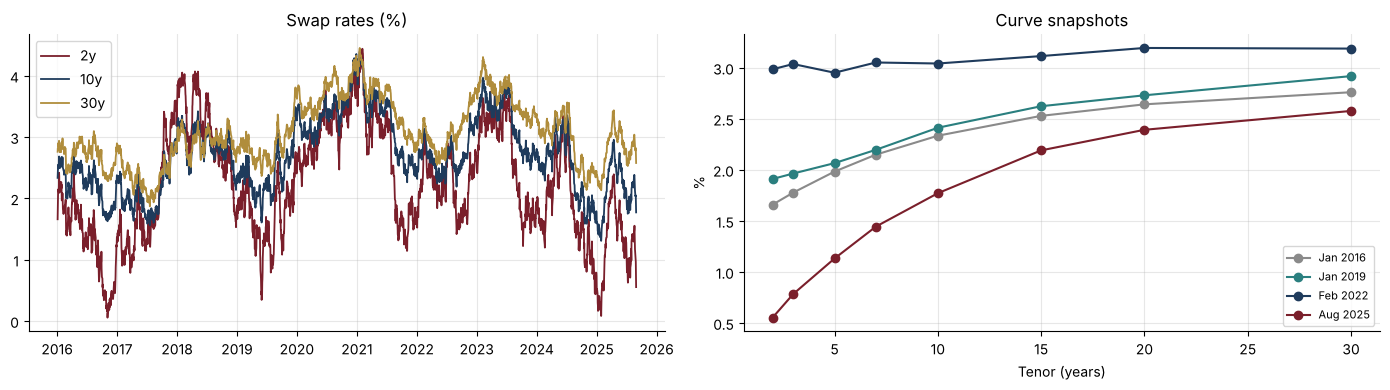

,2y,3y,5y,7y,10y,15y,20y,30y
Daily vol (bp),11.8,10.8,9.5,8.5,7.6,6.7,6.3,5.8


In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("rvpca.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/31-rates-relative-value-pca")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rvpca import (TENORS, simulate_curves, pca, fit_residuals, dv01_per_million, factor_exposure, curve_package,
                   package_pnl, mean_reversion_backtest, pnl_stats)

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL, GOLD = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f", "#b08d3c"
FORM = 504                                     # PCA estimated on the first two years only

curves, true_dislocation = simulate_curves(seed=6)
changes = curves.diff().iloc[1:] * 100          # daily changes in bp
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for col, c in zip(["2y", "10y", "30y"], [BORDEAUX, NAVY, GOLD]):
    axes[0].plot(curves[col], color=c, lw=1.3, label=col)
axes[0].set(title="Swap rates (%)"); axes[0].legend()
for d, c in zip(curves.index[[0, 800, 1600, -1]], [GREY, TEAL, NAVY, BORDEAUX]):
    axes[1].plot(TENORS, curves.loc[d], marker="o", color=c, label=d.strftime("%b %Y"))
axes[1].set(title="Curve snapshots", xlabel="Tenor (years)", ylabel="%"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("images/curves.png", dpi=150); plt.show()
changes.std().round(1).to_frame("Daily vol (bp)").T

## 1. PCA of daily curve moves (formation period)

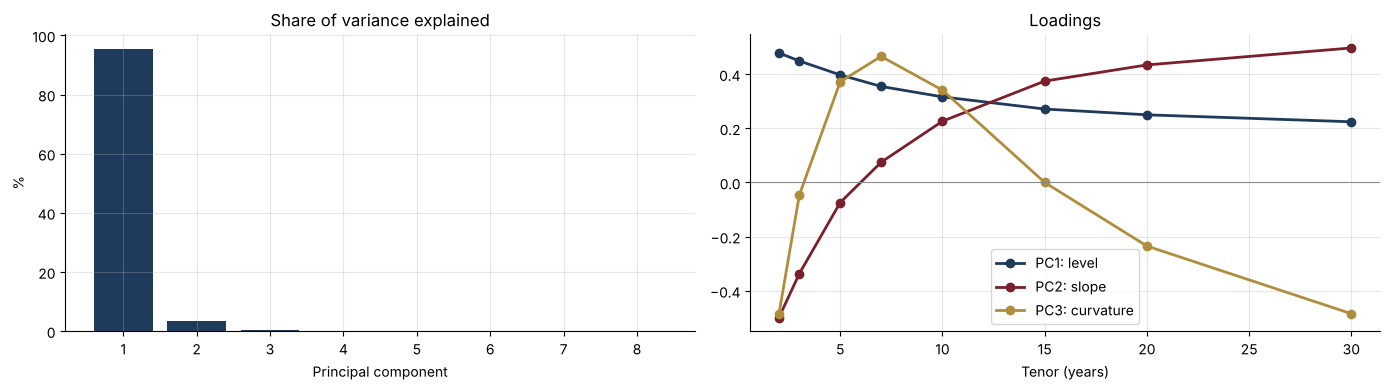

,PC1,PC2,PC3,PC4
% of variance,95.54,3.48,0.42,0.13


In [2]:
p = pca(changes.iloc[:FORM])
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(range(1, 9), p["explained"] * 100, color=NAVY)
axes[0].set(title="Share of variance explained", xlabel="Principal component", ylabel="%")
for k, (name, c) in enumerate(zip(["PC1: level", "PC2: slope", "PC3: curvature"], [NAVY, BORDEAUX, GOLD])):
    axes[1].plot(TENORS, p["loadings"].iloc[:, k], marker="o", color=c, lw=2, label=name)
axes[1].axhline(0, color=GREY, lw=0.8); axes[1].set(title="Loadings", xlabel="Tenor (years)"); axes[1].legend()
plt.tight_layout(); plt.savefig("images/pca.png", dpi=150); plt.show()
pd.Series(p["explained"][:4], index=["PC1", "PC2", "PC3", "PC4"]).mul(100).round(2).to_frame("% of variance").T

Three factors explain more than 99% of the variance, as in real swap curves. The first one is a
**level** move, but not a parallel one: its loading on the 2y is about twice its loading on the
30y, so the short end moves more. That detail is what breaks equal-DV01 hedging.

## 2. The risk of each tenor: DV01

In [3]:
last = curves.iloc[FORM]
dv01 = pd.Series({c: dv01_per_million(t, last[c]) for c, t in zip(curves.columns, TENORS)})
dv01.round(0).to_frame("DV01 per EUR 1m notional (EUR/bp)").T

,2y,3y,5y,7y,10y,15y,20y,30y
DV01 per EUR 1m notional (EUR/bp),190.0,282.0,460.0,627.0,862.0,1216.0,1524.0,2026.0


Positions below are expressed in **DV01** (EUR gained per bp fall in yield). To convert a DV01 into
a notional, divide by the line above: EUR 10,000 per bp on the 10y is about EUR 12m of notional.

## 3. Steepener: equal DV01 vs PCA weights

In [4]:
def exposures(pkg):
    return factor_exposure(pkg, p).round(0)

steep = {"DV01-neutral 2s10s": curve_package(["2y", "10y"], "dv01", p["loadings"]),
         "PCA-weighted 2s10s": curve_package(["2y", "10y"], "pca", p["loadings"])}
oos = changes.iloc[FORM - 1:]
rows = {}
for name, pkg in steep.items():
    pnl = package_pnl(pkg, oos)
    rows[name] = {"2y DV01": pkg["2y"], "10y DV01": pkg["10y"], **{f"P&L per 1-sd {k}": v for k, v in exposures(pkg).items()},
                  "Daily P&L vol, out of sample": pnl.std()}
pd.DataFrame(rows).T.round(0)

,2y DV01,10y DV01,P&L per 1-sd PC1,P&L per 1-sd PC2,P&L per 1-sd PC3,"Daily P&L vol, out of sample"
DV01-neutral 2s10s,10000.0,-10000.0,-37743.0,32155.0,12797.0,54735.0
PCA-weighted 2s10s,10000.0,-15137.0,0.0,37306.0,15507.0,42300.0


The equal-DV01 steepener is supposed to be a pure slope trade, yet a typical level move moves its
P&L more than a typical slope move does, and in a precise direction: it loses when rates rise. It
is a disguised **bet on rates falling**. Scaling the 10y leg up by the ratio of the PC1 loadings
(about 1.5 times) removes that exposure, and the out-of-sample P&L volatility falls by about 20%.

## 4. Butterfly: 50/50 DV01 wings vs PCA wings

The 2s10s30s fly is short the 10y belly for EUR 10,000 per bp and long the wings. The classic
50/50 split is neutral to a parallel shift only; the PCA wings are solved so that the package is
neutral to **both** level and slope and keeps only curvature and tenor-specific risk.

In [5]:
fly = {"50/50 DV01 fly": curve_package(["2y", "10y", "30y"], "dv01", p["loadings"]),
       "PCA-weighted fly": curve_package(["2y", "10y", "30y"], "pca", p["loadings"])}
rows = {}
for name, pkg in fly.items():
    pnl = package_pnl(pkg, oos)
    explained_by_pc12 = np.corrcoef(pnl, oos.values @ p["loadings"][["PC1", "PC2"]].values @ np.linalg.lstsq(
        oos.values @ p["loadings"][["PC1", "PC2"]].values, pnl.values, rcond=None)[0])[0, 1] ** 2
    rows[name] = {**{f"{k} DV01": v for k, v in pkg.items()}, **{f"P&L per 1-sd {k}": v for k, v in exposures(pkg).items()},
                  "Daily P&L vol, out of sample": pnl.std(), "Share of P&L variance from level + slope": explained_by_pc12}
fly_table = pd.DataFrame(rows).T
fly_table.round(2)

,2y DV01,10y DV01,30y DV01,P&L per 1-sd PC1,P&L per 1-sd PC2,P&L per 1-sd PC3,"Daily P&L vol, out of sample",Share of P&L variance from level + slope
50/50 DV01 fly,5000.00,-10000.0,5000.00,-8177.0,10082.0,12786.0,19937.40,0.52
PCA-weighted fly,3041.94,-10000.0,7611.17,-0.0,0.0,13271.0,14601.47,0.00


The 50/50 fly looks like a curvature trade, but because the 10y is not halfway between the 2y and
the 30y, it is also a slope and level position: about half of its daily P&L variance comes from
those two factors. The PCA fly takes about two and a half times more 30y than 2y, removes the level
and slope risk, and runs with about 27% less volatility for the same belly size.

## 5. Rich/cheap: what the three factors do not explain

Each day's curve is fitted on a constant plus the three PCA loadings. The residual of each tenor,
in bp, is the rich/cheap: positive means the tenor yields more than the factors justify (cheap).

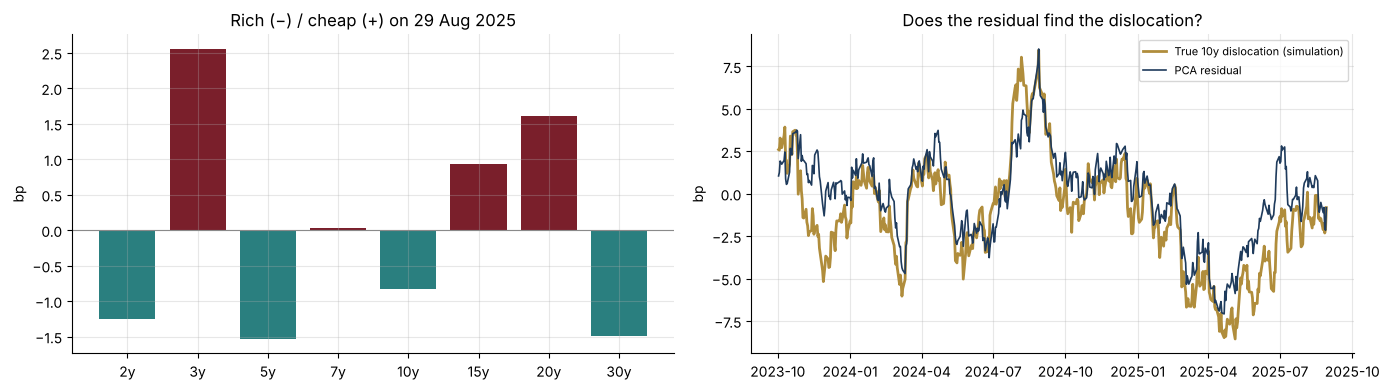

,2y,3y,5y,7y,10y,15y,20y,30y
Correlation with the true dislocation,0.48,0.84,0.51,0.44,0.85,0.85,0.78,0.63


In [6]:
resid = fit_residuals(curves, p["loadings"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
today = resid.iloc[-1]
axes[0].bar(today.index, today, color=[BORDEAUX if v > 0 else TEAL for v in today])
axes[0].axhline(0, color=GREY, lw=0.8); axes[0].set(title=f"Rich (−) / cheap (+) on {curves.index[-1]:%d %b %Y}", ylabel="bp")
axes[1].plot(true_dislocation["10y"].iloc[-500:], color=GOLD, lw=2, label="True 10y dislocation (simulation)")
axes[1].plot(resid["10y"].iloc[-500:], color=NAVY, lw=1.2, label="PCA residual")
axes[1].set(title="Does the residual find the dislocation?", ylabel="bp"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("images/rich_cheap.png", dpi=150); plt.show()
pd.Series({c: np.corrcoef(resid[c], true_dislocation[c])[0, 1] for c in curves.columns}).round(2).to_frame("Correlation with the true dislocation").T

The residual tracks the true dislocation well for the 3y, 10y and 15y (correlation of about 0.85)
but less well for the 2y, 5y and 7y (about 0.45 to 0.5). With four parameters fitted on eight
points, part of each dislocation is absorbed by the fit itself, so a rich/cheap reading is a
starting point for a trade idea, not a measurement.

## 6. Trading the butterfly out of sample

Rule: z-score of the fly level against its previous 60 days. Above +1.5 (belly cheap), receive the
belly and pay the wings; below −1.5, the reverse; exit inside ±0.25. Signals at the close are traded
the next day, and every leg traded pays 0.2 bp of bid-offer on its DV01.

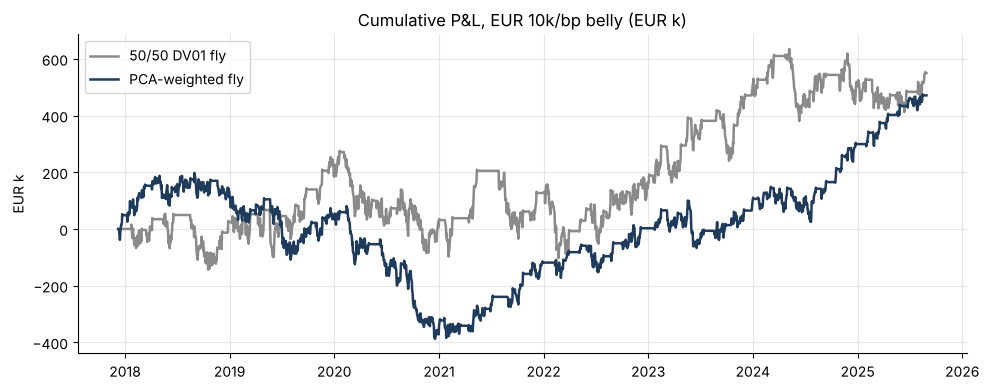

,Annual P&L (EUR),Annual vol (EUR),Sharpe,Max drawdown (EUR),Round trips
50/50 DV01 fly,68710.30,253237.77,0.27,-378001.62,51.0
PCA-weighted fly,58905.32,184723.92,0.32,-585810.59,56.0


In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
rows = {}
for (name, pkg), c in zip(fly.items(), [GREY, NAVY]):
    pnl, z, pos = mean_reversion_backtest(curves, pkg, cost_bp=0.2)
    pnl = pnl.iloc[FORM:]
    ax.plot(pnl.cumsum() / 1e3, color=c, lw=1.8, label=name)
    rows[name] = {**pnl_stats(pnl), "Round trips": int((np.diff(pos[FORM:]) != 0).sum() / 2)}
ax.set(title="Cumulative P&L, EUR 10k/bp belly (EUR k)", ylabel="EUR k"); ax.legend()
plt.tight_layout(); plt.savefig("images/fly_backtest.png", dpi=150); plt.show()
pd.DataFrame(rows).T.round(2)

On this history the PCA fly has a slightly higher Sharpe ratio with about 27% less volatility,
but a deeper worst drawdown. One history proves little, so the next section repeats the test.

## 7. Robustness over 8 simulated curve histories

In [8]:
grid = []
for seed in range(8):
    cv, _ = simulate_curves(seed=seed)
    ch = cv.diff().iloc[1:] * 100
    pp = pca(ch.iloc[:FORM])
    row = {"seed": seed}
    for kind, label in [("dv01", "50/50 DV01 fly"), ("pca", "PCA-weighted fly")]:
        pkg = curve_package(["2y", "10y", "30y"], kind, pp["loadings"])
        pnl, _, _ = mean_reversion_backtest(cv, pkg, cost_bp=0.2)
        row[f"Sharpe: {label}"] = pnl_stats(pnl.iloc[FORM:])["Sharpe"]
        row[f"Daily vol: {label}"] = package_pnl(pkg, ch.iloc[FORM - 1:]).std()
    grid.append(row)
grid = pd.DataFrame(grid).set_index("seed")
pd.concat([grid, grid.mean().to_frame("Average").T]).round(2)

,Sharpe: 50/50 DV01 fly,Daily vol: 50/50 DV01 fly,Sharpe: PCA-weighted fly,Daily vol: PCA-weighted fly
0,1.02,19402.18,0.48,14559.98
1,0.96,19854.98,0.59,14705.18
2,0.24,19756.27,0.80,14458.84
3,0.61,20247.32,0.41,14793.97
4,0.57,19598.82,0.38,14380.63
5,0.22,19600.22,0.19,14508.99
6,0.27,19937.40,0.32,14601.47
7,0.04,19698.04,0.85,14752.72
Average,0.49,19761.90,0.50,14595.22


On average the two flies earn the **same Sharpe ratio** (about 0.5), with a wide spread from one
history to the next. The PCA weights do not create extra return; what they change is the risk.
The PCA fly runs with 25 to 27% less volatility in every history, and its P&L comes from
curvature and dislocations only. Half of the 50/50 fly's P&L variance comes from level and slope,
so its result depends on a curve view the trader did not mean to take.

## Conclusions
- Three PCA factors describe the curve, and the first one is not a parallel shift. Equal-DV01
  packages therefore carry factor risk they were not designed to carry: the DV01 steepener is
  partly a bet on rates falling, the 50/50 fly is partly a slope trade.
- PCA weights remove that risk by construction (tested), with lower P&L volatility out of sample
  for the same position size. In the backtest they leave the Sharpe ratio unchanged: they clean
  the trade, they do not make it more profitable.
- The residuals of a three-factor fit locate tenor-specific dislocations, but not equally well
  for every tenor.
- **Next steps:** real swap and bond curves, PCA re-estimated on a rolling window (loadings drift),
  carry and roll-down in the signal, and bond-specific factors (repo specials, futures
  cheapest-to-deliver) for government bond RV.